In [2]:
import numpy as np
import matplotlib.pyplot as plt

1. Cayley transform

In [3]:
# cayley transform: N = cayley(X,Y,Z)
# N * N^\T \pre I
def cayley(X, Y, Z, eps=1e-6):
    """Free X (k x q), Y (q x q), Z (m-q x q)  ->  N (m x q, m >= q) with N^T N < I."""
    q = Y.shape[0]
    M = X.T @ X + Y - Y.T + Z.T @ Z + eps * np.eye(q)
    IM_inv = np.linalg.inv(np.eye(q) + M)
    return np.vstack([(np.eye(q) - M) @ IM_inv, -2 * Z @ IM_inv])

In [4]:
# initialize random X, Y, Z
rng = np.random.default_rng(0)
m, q = 5, 3
X, Y, Z = rng.standard_normal((q, q)), rng.standard_normal((q, q)), rng.standard_normal((m - q, q))

In [5]:
# use cayley transform to compute N and check if N * N^\T \pre I
N = cayley(X, Y, Z)
print(N.shape, 'max eig N^T N:', np.linalg.eigvalsh(N.T @ N).max())  # < 1

(5, 3) max eig N^T N: 0.936879762652921


2. Direct parametrization of regional stability conditions

In [44]:
# initialize random d, z_i, X_1, Y_1, Z_1, X_2, Y_2, Z_2
nx, nd, nz = 2, 1, 4        # state, input, nonlinearity (here nz >= nx + nd so that U is tall)
alpha, s = 0.99, 1.0        # fixed decay rate and input bound
n = nx + nd + nz

d = rng.standard_normal(nz)
z = rng.standard_normal((nz, nx))   # row i is z_i
X1, Y1, Z1 = rng.standard_normal((nx, nx)), rng.standard_normal((nx, nx)), rng.standard_normal((nd+nz, nx))
X2, Y2, Z2 = rng.standard_normal((nx + nd, nx + nd)), rng.standard_normal((nx + nd, nx + nd)), rng.standard_normal((nz - nx - nd, nx + nd))

In [45]:
# build Lambda from d
Lam = np.diag(np.exp(d))

# build R_\Lambda from \Lambda
R_Lam = np.linalg.cholesky(2 * Lam)   # R_Lam R_Lam^T = 2 Lambda
T2 = np.linalg.inv(R_Lam).T
R_Lam_t = np.linalg.cholesky(Lam)
R_Lam_2 = np.sqrt(2) * R_Lam_t

print(f'R_Lam.T @ R_Lam = {R_Lam.T @ R_Lam}')
print(f'R_Lam_2.T @ R_Lam_2 = {R_Lam_2.T @ R_Lam_2}')
print(f'Lam = {Lam}')


R_Lam.T @ R_Lam = [[6.31743213 0.         0.         0.        ]
 [0.         0.18784151 0.         0.        ]
 [0.         0.         6.8334584  0.        ]
 [0.         0.         0.         2.80882765]]
R_Lam_2.T @ R_Lam_2 = [[6.31743213 0.         0.         0.        ]
 [0.         0.18784151 0.         0.        ]
 [0.         0.         6.8334584  0.        ]
 [0.         0.         0.         2.80882765]]
Lam = [[3.15871606 0.         0.         0.        ]
 [0.         0.09392075 0.         0.        ]
 [0.         0.         3.4167292  0.        ]
 [0.         0.         0.         1.40441382]]


In [46]:
# build \tilde h_i (\tilde H) from z_i
H_t = z / np.sqrt(1 + np.sum(z**2, axis=1, keepdims=True))   # ||h_i|| < 1
N_t = Lam @ H_t                                               # \tilde N = Lambda \tilde H

In [48]:
# build U from cayley using X_2, Y_2, Z_2
U = cayley(X2, Y2, Z2)   # (nx+nd) x nz,  U U^T < I
U.shape


(4, 3)

In [50]:
# build J
# Gt = R_Lam @ U                                   # G^T = R_Lam U = [K/alpha, s Dbar]
G = np.linalg.inv(T2) @ U # G = T^{-1} U, G = [1/alpha K, s Dbar] (nz x (nx+nd))
K, Dbar = alpha * G[:, :nx], G[:, nx:] / s
print(f'K shape {K.shape}, Dbar shape {Dbar.shape}, G shape {G.shape}')
J = np.block([
    [np.eye(nx+nd), -G.T],
    [-G, 2*Lam]
])
print(f'J shape {J.shape}')
J_sanity = np.block([
    [alpha**2 * np.eye(nx), np.zeros((nx, nd)), -K.T],
    [np.zeros((nd, nx)), np.eye(nd) / s**2, -Dbar.T],
    [-K, -Dbar, 2 * Lam],
])
# # build R_J
R_J = np.linalg.cholesky(J)   # R_J R_J^T = J


K shape (4, 2), Dbar shape (4, 1), G shape (4, 3)
J shape (7, 7)


In [51]:
# build V from cayley using X_1, Y_1, Z_1
V = cayley(X1, Y1, Z1).T   # V is wide (nx x n), so cayley builds V^T;  V^T V < I

In [52]:
# build W from V
W = V @ R_J.T   # V = W R_J^{-T}

In [53]:
# Extract \tilde C_2, \tilde N, \tilde A, \tilde B, \tilde B_2   (\tilde N = N_t from above)
A_t, B_t, B2_t = W[:, :nx], W[:, nx:nx + nd], W[:, nx + nd:]
D21 = np.linalg.solve(Lam, Dbar)       # Dbar = Lambda D21
C2_t = np.linalg.solve(Lam, K - N_t)   # K = Lambda C2 + N

In [54]:
# check if conditions \Fb < 0 and \Gb_i > 0 are satisfied
def check_conditions(A_t, B_t, B2_t, C2_t, D21, Lam, N_t):
    F = np.block([
        [-alpha**2 * np.eye(nx), np.zeros((nx, nd)), C2_t.T @ Lam + N_t.T, A_t.T],
        [np.zeros((nd, nx)), -np.eye(nd) / s**2, D21.T @ Lam, B_t.T],
        [Lam @ C2_t + N_t, Lam @ D21, -2 * Lam, B2_t.T],
        [A_t, B_t, B2_t, -np.eye(nx)],
    ])
    print('max eig F:', np.linalg.eigvalsh(F).max())   # < 0
    for i in range(nz):
        G_i = np.block([[Lam[i, i], N_t[i:i+1]], [N_t[i:i+1].T, Lam[i, i] * np.eye(nx)]])
        print(f'min eig G_{i}:', np.linalg.eigvalsh(G_i).min())   # > 0

check_conditions(A_t, B_t, B2_t, C2_t, D21, Lam, N_t)

max eig F: -0.01084354249127858
min eig G_0: 1.60829006337893
min eig G_1: 0.05201724066488385
min eig G_2: 0.38130916337928245
min eig G_3: 0.519735510510438


3. Gradient computation

In [55]:
# \hat \theta are now torch parameters, initialize as above
import torch
torch.set_default_dtype(torch.float64)

ne = 1
init = dict(d=d, z=z, X1=X1, Y1=Y1, Z1=Z1, X2=X2, Y2=Y2, Z2=Z2,
            C=rng.standard_normal((ne, nx)))   # C does not enter F, G_i -> free
th = {k: torch.nn.Parameter(torch.tensor(v)) for k, v in init.items()}

In [56]:
# \tilde \theta = \Gamma(\hat \theta) gives the Lure parameters of G
def cayley_t(X, Y, Z, eps=1e-6):
    I = torch.eye(Y.shape[0])
    M = X.T @ X + Y - Y.T + Z.T @ Z + eps * I
    IM_inv = torch.linalg.inv(I + M)
    return torch.vstack([(I - M) @ IM_inv, -2 * Z @ IM_inv])

def tblock(rows):   # torch version of np.block
    return torch.cat([torch.cat(r, dim=1) for r in rows], dim=0)

def Gamma(th):
    Lam = torch.diag(torch.exp(th['d']))
    R_Lam = torch.linalg.cholesky(2 * Lam)
    H_t = th['z'] / torch.sqrt(1 + (th['z']**2).sum(1, keepdim=True))
    N_t = Lam @ H_t
    U = cayley_t(th['X2'], th['Y2'], th['Z2'])
    Gt = R_Lam @ U
    K, Dbar = alpha * Gt[:, :nx], Gt[:, nx:] / s
    J = tblock([
        [alpha**2 * torch.eye(nx), torch.zeros(nx, nd), -K.T],
        [torch.zeros(nd, nx), torch.eye(nd) / s**2, -Dbar.T],
        [-K, -Dbar, 2 * Lam],
    ])
    R_J = torch.linalg.cholesky(J)
    V = cayley_t(th['X1'], th['Y1'], th['Z1']).T
    W = V @ R_J.T
    return dict(
        A=W[:, :nx], B=W[:, nx:nx + nd], B2=W[:, nx + nd:], C=th['C'],
        C2=torch.linalg.solve(Lam, K - N_t), D21=torch.linalg.solve(Lam, Dbar),
        Lam=Lam, H=H_t, N=N_t,   # certificate, for the checks and plots below
    )

lure = Gamma(th)
ref = dict(A=A_t, B=B_t, B2=B2_t, C2=C2_t, D21=D21)
print('matches numpy:', all(np.allclose(lure[k].detach(), v) for k, v in ref.items()))

matches numpy: True


In [57]:
# do a rollout of the Lure system parametrized by \tilde \theta
# package LureSystem with Delta = DznActivation: dzn(z) = z - sat(z), sat = Hardtanh(-1, 1)
from sysid.models.base import LureSystem, LureSystemClass, DznActivation

def rollout(p, d):
    """d: (batch, N, nd), x_0 = 0  ->  e_hat (batch, N, ne), x (batch, N+1, nx)"""
    Z = torch.zeros
    G = LureSystem(LureSystemClass(
        A=p['A'], B=p['B'], B2=p['B2'], C=p['C'], D=Z(ne, nd), D12=Z(ne, nz),
        C2=p['C2'], D21=p['D21'], D22=Z(nz, nz), Delta=DznActivation(),
    ))
    e_hat, (x, _), _ = G(d.unsqueeze(-1), Z(d.shape[0], nx, 1))
    return e_hat.squeeze(-1), x.squeeze(-1)

e_hat, x = rollout(lure, torch.randn(3, 100, nd))
print(e_hat.shape, x.shape)

torch.Size([3, 100, 1]) torch.Size([3, 101, 2])


In [58]:
# calculate a loss for a sample input trajectory from the training dataset
# training data is found in the csv files 'notebooks/Duffing/datasets/id/train'
from sysid.data.direct_loader import load_csv_folder
from sysid.data.normalizer import DataNormalizer

us, ys, _, _ = load_csv_folder('Duffing/datasets/id/train', input_col=['u'], output_col=['q'])   # relative to notebooks/
normalizer = DataNormalizer(method='scale_only')
normalizer.fit(np.concatenate(us)[None], np.concatenate(ys)[None])   # statistics over all training files

n_samples, N_seq, washout = 4, 700, 500   # few samples; length and warmup as in crnn_gen-sec_duffing.yaml
u = torch.tensor(normalizer.transform_inputs(np.stack([a[:N_seq] for a in us[:n_samples]])))
y = torch.tensor(normalizer.transform_outputs(np.stack([a[:N_seq] for a in ys[:n_samples]])))

def loss_fn(th):   # \hat\theta -> \Gamma -> rollout -> MSE after the washout
    e_hat, _ = rollout(Gamma(th), u)
    return torch.mean((e_hat[:, washout:] - y[:, washout:])**2)

loss = loss_fn(th)
print('loss:', loss.item())

loss: 1.5087625992545695


In [59]:
# calculate a gradient on the learnable parameters \hat \theta using the loss from above
for p in th.values():
    p.grad = None
loss.backward()
for k, p in th.items():
    print(f'{k:3s} |grad| = {p.grad.norm():.3e}')

d   |grad| = 1.967e-02
z   |grad| = 4.432e-02
X1  |grad| = 1.094e-02
Y1  |grad| = 1.825e-03
Z1  |grad| = 1.976e-02
X2  |grad| = 3.732e-02
Y2  |grad| = 1.928e-02
Z2  |grad| = 3.546e-02
C   |grad| = 3.675e-02


4. Training loop on a few samples

step  0  loss 1.5088
step 10  loss 1.4771
step 20  loss 1.4275
step 30  loss 1.4068
step 40  loss 1.3846


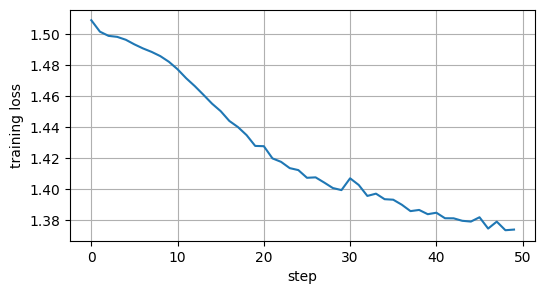

In [60]:
# a few Adam steps on \hat \theta: unconstrained, so no barrier, rollback or projection needed
opt = torch.optim.Adam(th.values(), lr=2e-2)
losses = []
for step in range(50):
    opt.zero_grad()
    loss = loss_fn(th)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(th.values(), 1.0)   # as in crnn_gen-sec_duffing.yaml
    opt.step()
    losses.append(loss.item())
    if step % 10 == 0:
        print(f'step {step:2d}  loss {loss.item():.4f}')

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(losses)
ax.set_xlabel('step'); ax.set_ylabel('training loss'); ax.grid()

In [61]:
# the trained parameters still satisfy \Fb < 0 and \Gb_i > 0, by construction
p = {k: v.detach().numpy() for k, v in Gamma(th).items()}
check_conditions(p['A'], p['B'], p['B2'], p['C2'], p['D21'], p['Lam'], p['N'])

max eig F: -0.0017797559592531696
min eig G_0: 1.3504130350501204
min eig G_1: 0.4584145263348488
min eig G_2: 0.2827363861053408
min eig G_3: 0.16492594793000082


5. Visualizations

1 trajectories satisfy the input condition, 3 violate it


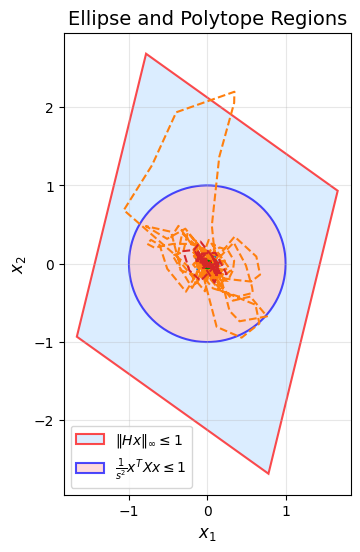

In [62]:
# ellipse x^T P~ x <= 1 (P~ = I, so the unit ball) inside the parallelogram ||H~ x||_inf <= 1, with the state trajectories
# a trajectory is red if it violates the input condition ||d_k||^2 <= s^2 (1 - alpha^2 ||x_k||^2) somewhere (c > 0)
from sysid.utils import plot_safe_set_trajectories

with torch.no_grad():
    p = Gamma(th)
    e_hat, x = rollout(p, u)
c = (u**2).sum(-1) / s**2 - 1 + alpha**2 * (x[:, :-1]**2).sum(-1)
fig, ax, n_ok, n_bad = plot_safe_set_trajectories(np.eye(nx), p['H'].numpy(), 1.0, x.numpy(), c.numpy())
ax.set_aspect('equal')
print(f'{n_ok} trajectories satisfy the input condition, {n_bad} violate it')

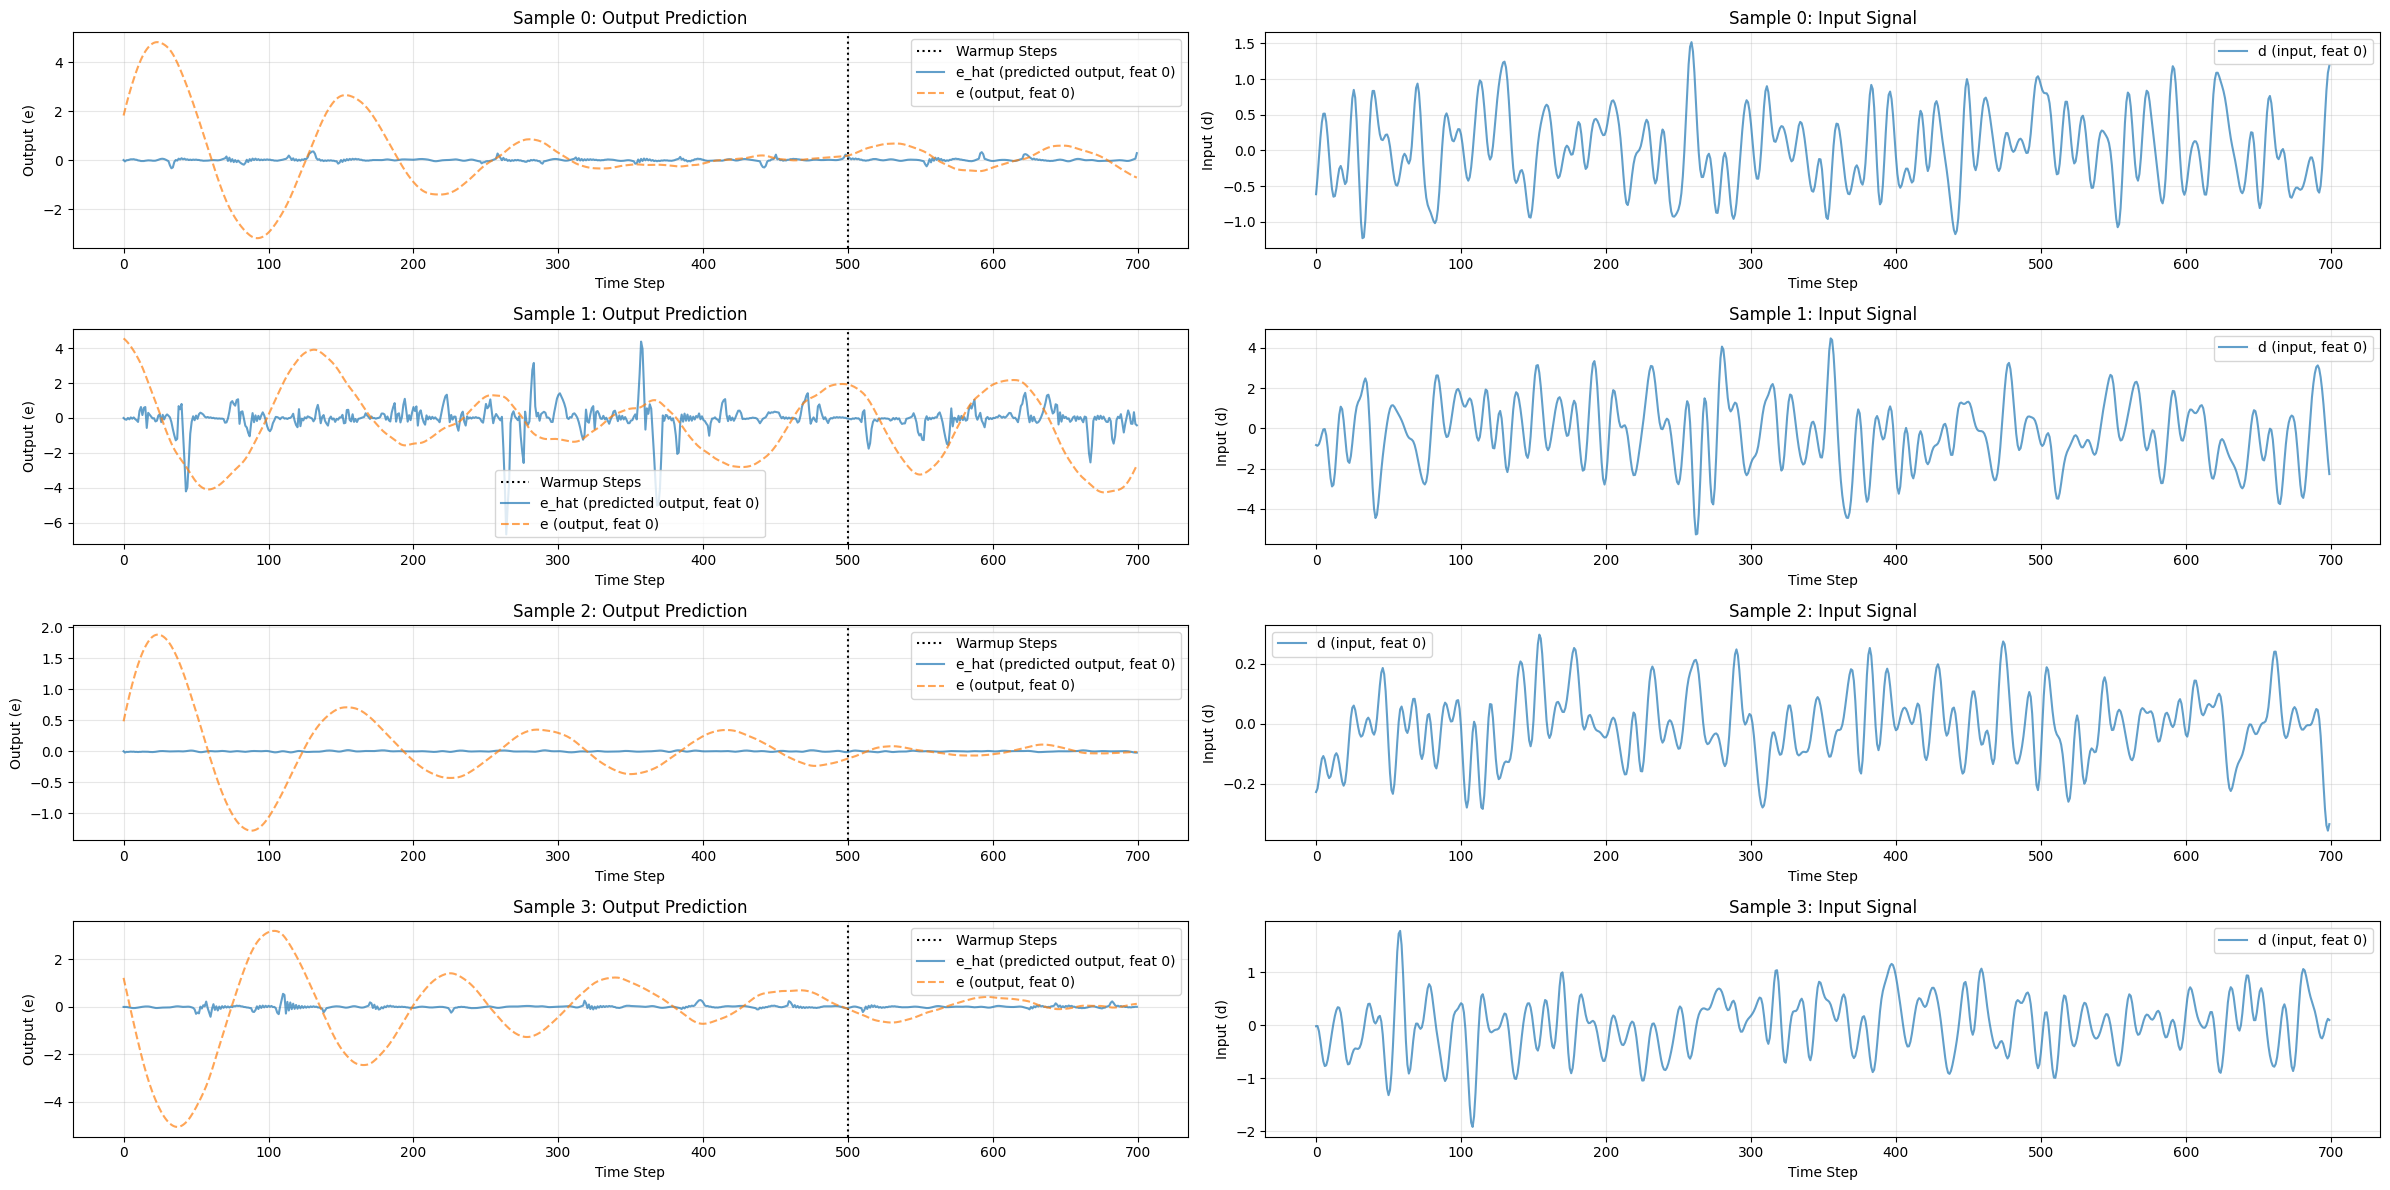

In [63]:
# predictions of the Lure model alongside the true outputs (normalized); dotted line = end of washout
from sysid.utils import plot_predictions

fig, axes = plot_predictions('.', e_hat.numpy(), y.numpy(), u.numpy(), num_samples=n_samples,
                             warmup_steps=washout, return_axes=True)